In [1]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [5]:
import zipfile
from pathlib import Path

archivo_zip = Path.home() / "Downloads" / "1745432589128-superstore_dataset2012.zip"

with zipfile.ZipFile(archivo_zip, "r") as zip_ref:
    print(zip_ref.namelist())

['superstore_dataset2012.csv']


In [6]:
with zipfile.ZipFile(archivo_zip, "r") as zip_ref:
    with zip_ref.open("superstore_dataset2012.csv") as archivo_csv:
        df = pd.read_csv(archivo_csv, encoding="latin1")

print("Dimensiones:", df.shape)
display(df.head())
print("Columnas:", df.columns.tolist())

Dimensiones: (4246, 24)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,21896,ID-2012-71858,1/2/2012,7/2/2012,Standard Class,CP-12085,Cathy Prescott,Corporate,Jakarta,Jakarta,...,TEC-PH-10003784,Technology,Phones,"Motorola Signal Booster, with Caller ID",593.9895,5,0.17,-71.7105,52.22,Medium
1,4323,MX-2012-154459,1/2/2012,6/2/2012,Standard Class,JF-15190,Jamie Frazer,Consumer,Santiago,Santiago,...,TEC-PH-10002102,Technology,Phones,"Nokia Headset, Cordless",151.9200,3,0.00,71.4000,32.94,High
2,2829,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,TEC-AC-10002760,Technology,Accessories,"Memorex Memory Card, Erganomic",200.1600,3,0.00,0.0000,28.95,High
3,2828,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,FUR-CH-10001423,Furniture,Chairs,"Harbour Creations Rocking Chair, Black",192.8800,2,0.00,54.0000,19.27,High
4,6762,MX-2012-151904,1/2/2012,3/2/2012,First Class,DJ-13420,Denny Joy,Corporate,Villa Canales,Guatemala,...,OFF-PA-10003571,Office Supplies,Paper,"Enermax Cards & Envelopes, Recycled",94.0200,3,0.00,1.8600,10.73,Medium


Columnas: ['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']


In [7]:
# Información general y tipos de datos
df.info()

# Cantidad de valores nulos por columna
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Mostrar algunas filas para revisar los datos
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 4246 entries, 0 to 4245
Data columns (total 24 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Row ID          4246 non-null   int64  
 1   Order ID        4246 non-null   str    
 2   Order Date      4246 non-null   str    
 3   Ship Date       4246 non-null   str    
 4   Ship Mode       4246 non-null   str    
 5   Customer ID     4246 non-null   str    
 6   Customer Name   4246 non-null   str    
 7   Segment         4246 non-null   str    
 8   City            4246 non-null   str    
 9   State           4246 non-null   str    
 10  Country         4246 non-null   str    
 11  Postal Code     823 non-null    float64
 12  Market          4246 non-null   str    
 13  Region          4246 non-null   str    
 14  Product ID      4246 non-null   str    
 15  Category        4246 non-null   str    
 16  Sub-Category    4246 non-null   str    
 17  Product Name    4246 non-null   str    
 18 

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,City,State,...,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Shipping Cost,Order Priority
0,21896,ID-2012-71858,1/2/2012,7/2/2012,Standard Class,CP-12085,Cathy Prescott,Corporate,Jakarta,Jakarta,...,TEC-PH-10003784,Technology,Phones,"Motorola Signal Booster, with Caller ID",593.9895,5,0.17,-71.7105,52.22,Medium
1,4323,MX-2012-154459,1/2/2012,6/2/2012,Standard Class,JF-15190,Jamie Frazer,Consumer,Santiago,Santiago,...,TEC-PH-10002102,Technology,Phones,"Nokia Headset, Cordless",151.9200,3,0.00,71.4000,32.94,High
2,2829,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,TEC-AC-10002760,Technology,Accessories,"Memorex Memory Card, Erganomic",200.1600,3,0.00,0.0000,28.95,High
3,2828,MX-2012-114461,1/2/2012,5/2/2012,Standard Class,RM-19375,Raymond Messe,Consumer,Escuintla,Escuintla,...,FUR-CH-10001423,Furniture,Chairs,"Harbour Creations Rocking Chair, Black",192.8800,2,0.00,54.0000,19.27,High
4,6762,MX-2012-151904,1/2/2012,3/2/2012,First Class,DJ-13420,Denny Joy,Corporate,Villa Canales,Guatemala,...,OFF-PA-10003571,Office Supplies,Paper,"Enermax Cards & Envelopes, Recycled",94.0200,3,0.00,1.8600,10.73,Medium


In [8]:
# Detectar y convertir columnas cuyo nombre incluya "Date"
columnas_fecha = [col for col in df.columns if "date" in col.lower()]

for columna in columnas_fecha:
    df[columna] = pd.to_datetime(df[columna], errors="coerce")

print("Columnas de fecha:", columnas_fecha)
print(df[columnas_fecha].dtypes)

Columnas de fecha: ['Order Date', 'Ship Date']
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [9]:
print("Columnas:")
print(df.columns.tolist())

print("\nValores nulos por columna:")
print(df.isnull().sum().sort_values(ascending=False))

print("\nTipos de datos:")
print(df.dtypes)

Columnas:
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'City', 'State', 'Country', 'Postal Code', 'Market', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Shipping Cost', 'Order Priority']

Valores nulos por columna:
Postal Code       3423
Ship Date         1411
Order ID             0
Row ID               0
Ship Mode            0
Customer ID          0
Customer Name        0
Order Date           0
Segment              0
City                 0
State                0
Country              0
Market               0
Region               0
Product ID           0
Category             0
Sub-Category         0
Product Name         0
Sales                0
Quantity             0
Discount             0
Profit               0
Shipping Cost        0
Order Priority       0
dtype: int64

Tipos de datos:
Row ID                     int64
Order ID                     str
Order Dat

In [10]:
# Postal Code es un código, así que lo guardamos como texto
df["Postal Code"] = df["Postal Code"].astype("Int64").astype("string")

# Mantener los valores faltantes como <NA> y asegurar el formato de fecha
df["Ship Date"] = pd.to_datetime(df["Ship Date"], errors="coerce")

# Comprobar los cambios
print("Filas y columnas:", df.shape)
print("Nulos en Postal Code:", df["Postal Code"].isna().sum())
print("Nulos en Ship Date:", df["Ship Date"].isna().sum())
print("Tipo de Ship Date:", df["Ship Date"].dtype)

Filas y columnas: (4246, 24)
Nulos en Postal Code: 3423
Nulos en Ship Date: 1411
Tipo de Ship Date: datetime64[us]


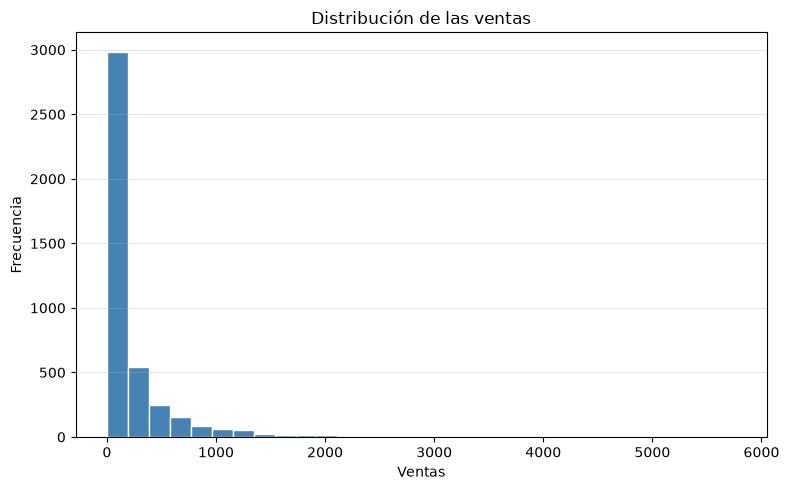

In [11]:
plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=30, color="steelblue", edgecolor="white")

plt.title("Distribución de las ventas")
plt.xlabel("Ventas")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

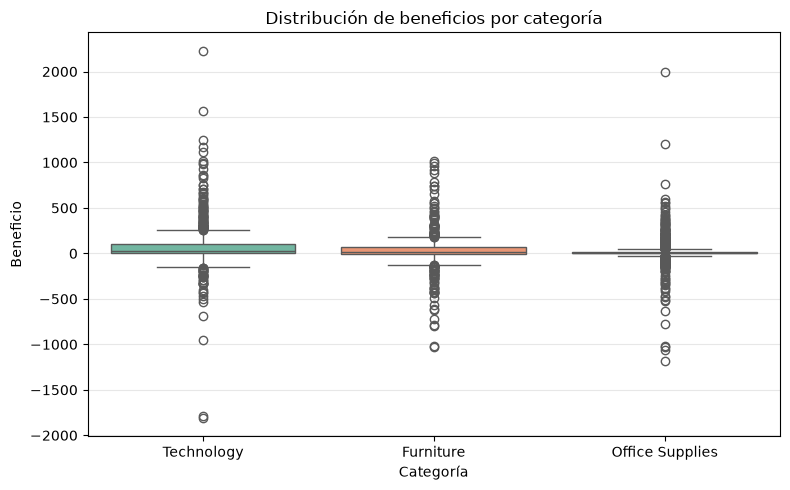

In [12]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="Category", y="Profit", hue="Category", palette="Set2", legend=False)

plt.title("Distribución de beneficios por categoría")
plt.xlabel("Categoría")
plt.ylabel("Beneficio")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

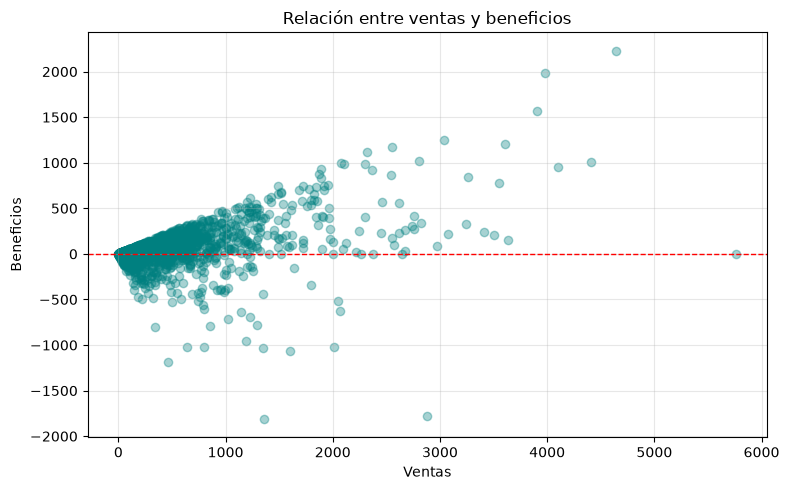

In [13]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Sales"], df["Profit"], alpha=0.35, color="teal")

plt.title("Relación entre ventas y beneficios")
plt.xlabel("Ventas")
plt.ylabel("Beneficios")
plt.axhline(0, color="red", linestyle="--", linewidth=1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

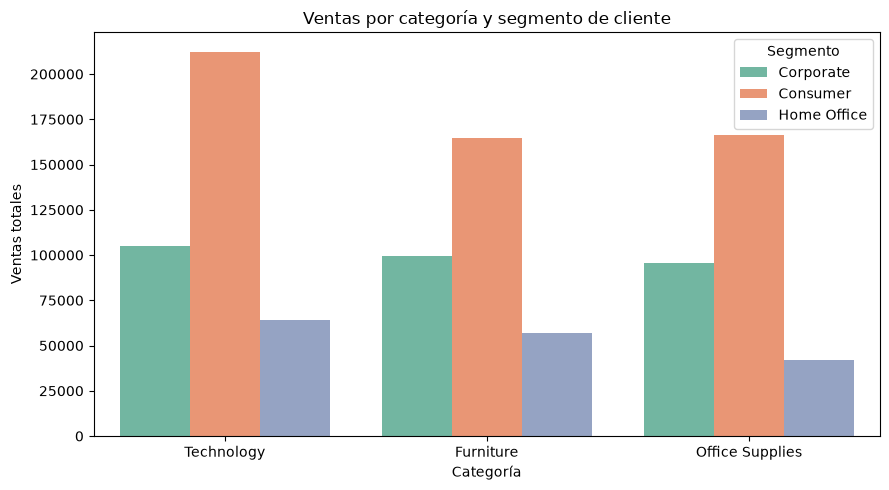

In [14]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=df,
    x="Category",
    y="Sales",
    hue="Segment",
    estimator="sum",
    errorbar=None,
    palette="Set2"
)

plt.title("Ventas por categoría y segmento de cliente")
plt.xlabel("Categoría")
plt.ylabel("Ventas totales")
plt.legend(title="Segmento")
plt.tight_layout()
plt.show()

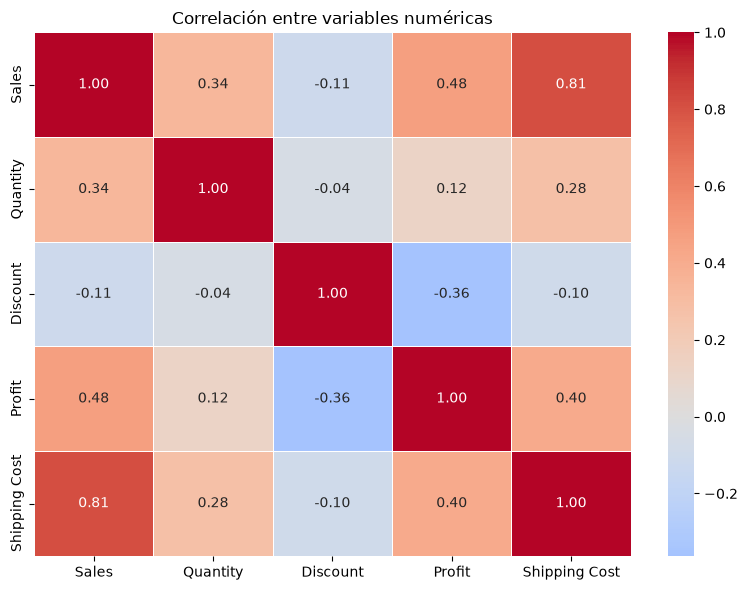

In [15]:
columnas_numericas = ["Sales", "Quantity", "Discount", "Profit", "Shipping Cost"]

correlaciones = df[columnas_numericas].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    correlaciones,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlación entre variables numéricas")
plt.tight_layout()
plt.show()

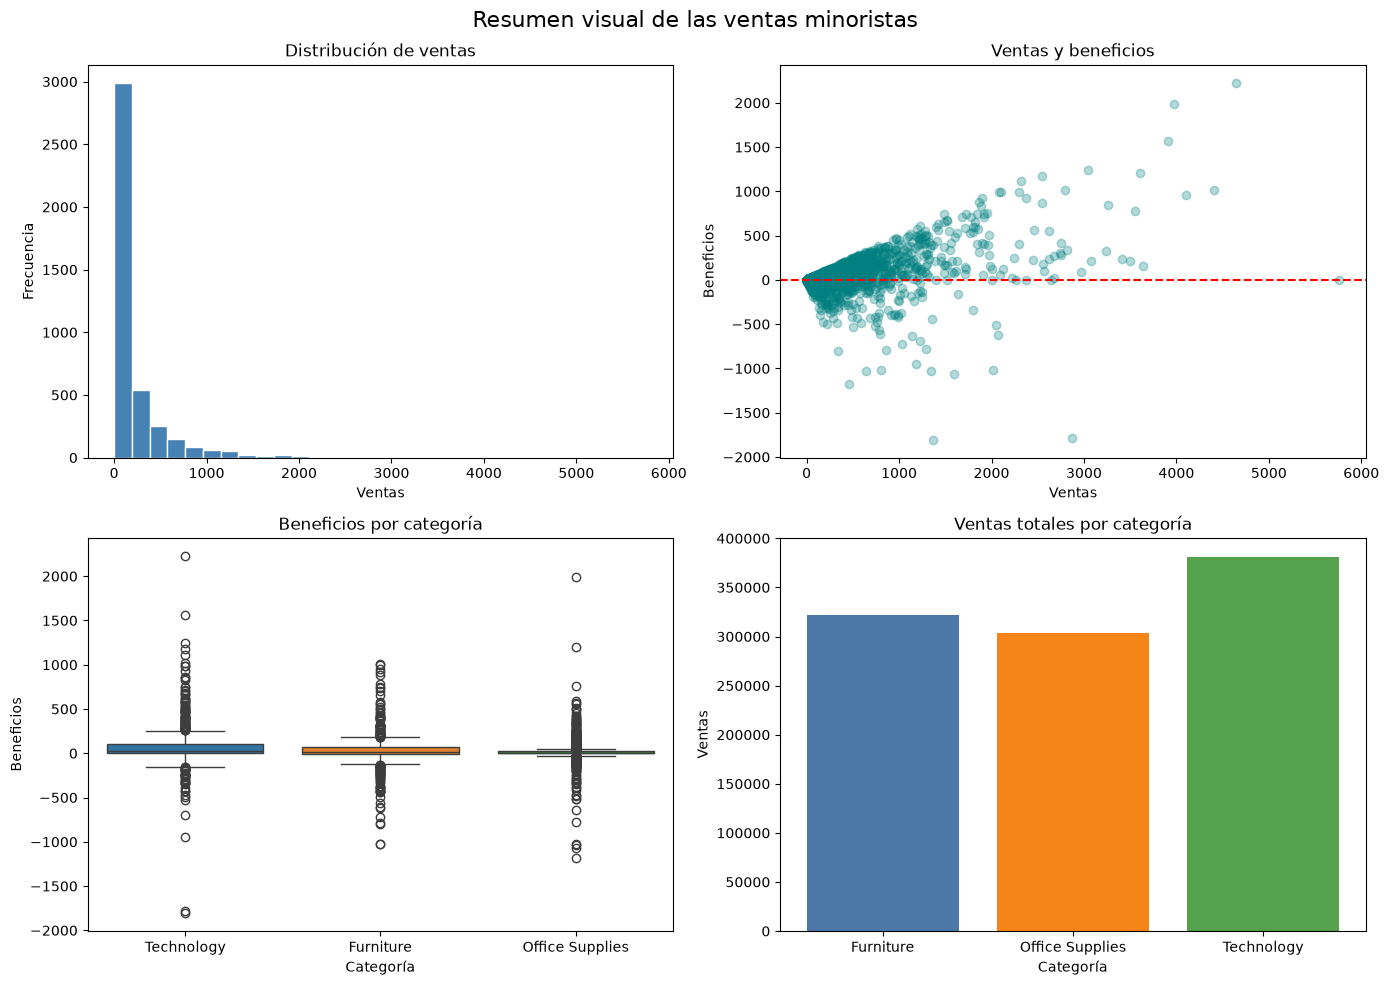

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Histograma: muestra la distribución de las ventas.
axes[0, 0].hist(df["Sales"], bins=30, color="steelblue", edgecolor="white")
axes[0, 0].set_title("Distribución de ventas")
axes[0, 0].set_xlabel("Ventas")
axes[0, 0].set_ylabel("Frecuencia")

# 2. Dispersión: permite observar la relación entre ventas y beneficios.
axes[0, 1].scatter(df["Sales"], df["Profit"], alpha=0.3, color="teal")
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[0, 1].set_title("Ventas y beneficios")
axes[0, 1].set_xlabel("Ventas")
axes[0, 1].set_ylabel("Beneficios")

# 3. Boxplot: compara la distribución de beneficios por categoría.
sns.boxplot(
    data=df, x="Category", y="Profit",
    hue="Category", legend=False, ax=axes[1, 0]
)
axes[1, 0].set_title("Beneficios por categoría")
axes[1, 0].set_xlabel("Categoría")
axes[1, 0].set_ylabel("Beneficios")

# 4. Barras: compara las ventas totales por categoría.
ventas_categoria = df.groupby("Category")["Sales"].sum()
axes[1, 1].bar(
    ventas_categoria.index, ventas_categoria.values,
    color=["#4C78A8", "#F58518", "#54A24B"]
)
axes[1, 1].set_title("Ventas totales por categoría")
axes[1, 1].set_xlabel("Categoría")
axes[1, 1].set_ylabel("Ventas")

fig.suptitle("Resumen visual de las ventas minoristas", fontsize=16)
fig.tight_layout()
fig.savefig("resumen_visualizaciones.png", dpi=300, bbox_inches="tight")
plt.show()